# Kayak : collecter, stocker et préparer les données de destinations

*Certification RNCP35288 (Concepteur Développeur en Science des Données), bloc 1 :
construction et alimentation d'une infrastructure de gestion de données.*

**Objet** : recommander des destinations en France selon **la météo** et **les hôtels**.
Le pipeline collecte les données de 35 villes, les dépose dans un **data lake** (S3), les
nettoie et les charge dans un **entrepôt SQL** (RDS) par un **ETL** Spark, puis cartographie
les **5 meilleures destinations** et les **20 meilleurs hôtels**.

**Ce notebook présente le pipeline et ses résultats.** Le code est dans le paquet `kayak/`
(collecte, stockage, ETL Spark, cartes), testé par `pytest` (dossier `tests/`) ; la commande
`python -m kayak.pipeline` rejoue toutes les étapes. Ici, on relit ce que la collecte du
11 octobre 2026 a déposé dans le data lake, on relance l'ETL Spark en direct, on interroge
l'entrepôt en SQL et on affiche les cartes. **Chaque chiffre cité dans le texte est calculé
par une cellule de code exécutée juste avant.**

| Compétence du référentiel (bloc 1) | Où |
|---|---|
| C1.1 Architecture : data lake et data warehouse | sections 1, 4, 5 ; étude (PDF) |
| C1.2 Calcul distribué (Spark) | section 4 (`kayak/etl/spark_etl.py`) |
| C1.3 Collecte web (BeautifulSoup, Scrapy, API) conforme au RGPD | sections 2 et 3 |
| C1.4 ETL : nettoyer et organiser les données dans l'entrepôt | sections 4 et 5 |
| Qualité des données extraites ; accessibilité dans l'entrepôt | sections 3 à 5 |

### Fiche de documentation vivante du notebook

*Cinq rubriques (règle de documentation) : CHOIX, OÙ, COMMENT, POURQUOI, JOURNALISATION.*

## CHOIX

- **Retenu : un notebook de présentation, et le code dans le paquet `kayak/`.** Les cellules
  appellent le paquet ; les fonctions d'aide propres au notebook (volumes, bilan Overpass, image
  allégée) sont dans `kayak/outils_notebook.py`, où elles sont testées. *Écarté* : tout écrire
  dans les cellules, qui n'auraient aucun test direct ni inverse.
- **Retenu : relire le data lake archivé et rejouer l'ETL Spark dessus (hors ligne).** Le
  notebook ne collecte rien : les données du 11/10/2026 sont dans `datalake/`. *Écarté* :
  relancer la collecte à chaque exécution, car les services tiers répondent différemment d'un
  jour à l'autre (prévisions révisées, centres de villes déplacés, serveur Overpass occupé,
  Booking.com qui bloque le robot) : les chiffres cités dans le texte ne seraient plus
  reproductibles.
- **Retenu : chaque chiffre du texte est calculé par la cellule exécutée juste avant.** *Écarté*
  : des chiffres recopiés à la main, qui dériveraient sans que rien ne le signale.

## OÙ

- **Rôle** : livrable de présentation du bloc 1 (collecte, data lake, ETL Spark, entrepôt SQL,
  cartes). Il vient après la collecte et ne la remplace pas.
- **Appelle** : `kayak.stockage.data_lake`, `kayak.collecte.robots`,
  `kayak.collecte.destinations` et `kayak.collecte.booking_spider` (une constante et une
  fonction pure), `kayak.collecte.hotels_osm` (lecture des archives seulement),
  `kayak.etl.spark_etl.executer_etl`, `kayak.cartes`, `kayak.outils_notebook`.
- **Lit** : `datalake/` et `entrepot/requetes_exemple.sql`. **Écrit** : la zone `curated` du
  lac, `entrepot/kayak.db`, `sorties/` (cartes HTML et PNG).
- **Dépend de** : Java fourni par le paquet `jdk4py` (Spark), un navigateur Chromium pour
  l'export PNG de Kaleido, et `setuptools` (module `distutils` exigé par PySpark 3.5 sous Python
  3.12).
- **Source jumelle** : `Kayak_Bloc1_CDSD_source.py` (format « percent »), dont le notebook est
  généré.

## COMMENT

- Sections 1 à 7 : volumes du lac (1), destinations et météo (2), hôtels Booking puis
  OpenStreetMap (3), ETL Spark (4), requêtes SQL (5), cartes (6), RGPD et limites (7).
- **Mode hors ligne prouvé** : `tests/test_notebook.py` exécute le notebook dans une copie du
  projet avec une garde qui interdit toute connexion hors de la machine, navigateur de l'export
  PNG compris (voir tests/test_notebook.py:135), vérifie ensuite les chiffres clés, et deux
  tests inverses prouvent que la garde refuse une connexion sortante
  (tests/test_notebook.py:68) et que le mandataire du navigateur ne répond pas
  (tests/test_notebook.py:127).
- Les fonctions d'aide du notebook sont testées dans `tests/test_outils_notebook.py`.
- Seul le chargement du fond de carte (tuiles OpenStreetMap) passe par Internet, lors de
  l'export PNG de Kaleido ; ce n'est pas une collecte de données du projet. Hors ligne,
  l'export échoue : la section 6 l'écrit et affiche le dernier PNG exporté de `sorties/`.

## POURQUOI

- Besoin et compétences C1.1 à C1.4 : énoncé du bloc 1 (non joint à ce dépôt) et
  référentiel de la certification RNCP35288.
- Pourquoi rejouer l'ETL dans le notebook : `kayak/etl/spark_etl.py` est le code livré, et les
  chiffres du texte doivent venir de lui (voir kayak/etl/spark_etl.py:771).
- Pourquoi une garde hors ligne : relancer la collecte pour un simple affichage serait inutile
  et peu poli. Le refus du contrôle anti-robot de Booking.com est respecté, et la politique
  d'usage de Nominatim (https://operations.osmfoundation.org/policies/nominatim/) limite le
  débit à une requête par seconde.

## JOURNALISATION

- Le notebook n'écrit aucun fichier journal : il affiche ses constats avec `print`.
- Il relit le journal HTTP de la collecte du 11/10/2026 (`raw/journal_http`, 142 requêtes) et le
  résume dans la section 2.
- Les fonctions du paquet qu'il appelle journalisent avec `logging` (par exemple « ETL terminé »
  au niveau INFO par `kayak.etl.spark_etl`) ; le notebook ne configure pas `logging`, ces lignes
  INFO n'y sont donc pas affichées. Seuls les avertissements (WARNING) s'affichent : en
  section 6, « Export PNG impossible pour <carte> (<type de l'erreur>) » quand l'export échoue
  hors ligne, sans le texte de l'erreur (il citerait l'emplacement du navigateur sur le poste).

In [1]:
import io
import json
import os
import sqlite3
import time
from pathlib import Path

import pandas as pd

from kayak import config
from kayak.outils_notebook import (
    afficher,
    bilan_overpass,
    hotels_de,
    image_allegee,
    milliers,
    octets,
)
from kayak.pipeline import lire_parquet
from kayak.stockage.data_lake import DataLake

DATE = "2026-10-11"  # collecte COMPLÈTE : c'est elle qui sert à tous les résultats
DATE_PREMIERE = "2026-10-10"  # première collecte (échantillon plafonné), gardée comme archive
os.environ["KAYAK_DATE_COLLECTE"] = DATE
lake = DataLake()
print("Data lake :", lake.mode, "| entrepôt :", config.DB_URL.split("///")[0] + "///…")

Data lake : local | entrepôt : sqlite:///…


## 1. Le data lake : ce que les collectes ont déposé

Organisation par **zones** et par **date** : `raw/<source>/date=AAAA-MM-JJ/` garde les données
telles que reçues (traçabilité, rejouabilité), `curated/` les données nettoyées et enrichies
(tables **Parquet** et CSV enrichi écrits par Spark). En local, le data lake est un dossier ;
en production, le même code écrit dans un bucket S3 (variable `KAYAK_S3_BUCKET`), avec
chiffrement côté serveur.

**Deux collectes, deux partitions.** `date=2026-10-10` est la **première collecte** : sa
requête Overpass était plafonnée à 40 éléments par ville (voir section 3) ; elle est conservée
comme archive, avec la preuve du refus de Booking.com. `date=2026-10-11` est la **collecte
complète**, faite avec le code corrigé : **c'est elle qui sert à tous les résultats de ce
notebook** (ETL, entrepôt, cartes).

In [2]:
fichiers = sorted(lake.lister(""))
partitions = pd.DataFrame(
    {
        "zone": ["/".join(f.split("/")[:2]) for f in fichiers],
        "date": [
            next((p[5:] for p in f.split("/") if p.startswith("date=")), "") for f in fichiers
        ],
    }
)
print(f"{len(fichiers)} fichiers dans le data lake, une partition par date de collecte :")
afficher(partitions.groupby(["zone", "date"]).size().unstack(fill_value=0))
for jour in (DATE_PREMIERE, DATE):
    present = lake.existe(f"raw/destinations/date={jour}/page.html")
    print(f"HTML brut de la page source (page.html), collecte du {jour} :",
          "présent" if present else "absent de la livraison")

196 fichiers dans le data lake, une partition par date de collecte :


date,2026-10-10,2026-10-11
zone,,
curated/kayak_enrichi,2,2
curated/villes,1,1
raw/booking,2,2
raw/destinations,1,3
raw/geocodage,36,36
raw/journal_http,0,1
raw/meteo,1,36
raw/osm,36,36


HTML brut de la page source (page.html), collecte du 2026-10-10 : absent de la livraison
HTML brut de la page source (page.html), collecte du 2026-10-11 : absent de la livraison


> **À propos de `page.html`** : la collecte archive à chaque exécution le HTML brut de la page
> source (`kayak/collecte/destinations.py`), mais ce fichier **n'est volontairement pas livré**
> avec le data lake : c'est le contenu d'un site tiers, qu'on n'a pas à redistribuer. Seul le
> CSV réconcilié (`destinations.csv`) est livré. Le tableau ci-dessus en témoigne : la zone
> `raw/destinations` ne contient pour chaque date que le CSV, le `robots.txt` du site et ses
> métadonnées.

**Volume du data lake** : mesuré sur les fichiers eux-mêmes. C'est ce chiffre, et non une
estimation, qui sert de base à l'étude d'architecture (`Etude_architecture_Kayak.pdf`).

In [3]:
nb_villes = len(pd.read_csv(lake.chemin_local(f"raw/destinations/date={DATE}/destinations.csv")))


# Unités décimales partout : 1 Ko = 1 000 octets, 1 Mo = 1 000 000 octets.
collecte = [f for f in fichiers if f.startswith("raw/") and f"date={DATE}" in f]
premiere = [f for f in fichiers if f.startswith("raw/") and f"date={DATE_PREMIERE}" in f]
curated = [f for f in fichiers if f.startswith("curated/") and f"date={DATE}" in f]
o_collecte, o_premiere = octets(lake, collecte), octets(lake, premiere)
o_total = octets(lake, fichiers)
print(f"Collecte complète du {DATE} (zone raw) : {len(collecte)} fichiers, "
      f"{milliers(o_collecte)} octets = {o_collecte / 1e6:.2f} Mo")
print(f"Première collecte du {DATE_PREMIERE} (zone raw) : {len(premiere)} fichiers, "
      f"{milliers(o_premiere)} octets = {o_premiere / 1e6:.2f} Mo")
print(f"Zone curated de la collecte du {DATE} : {len(curated)} fichiers, "
      f"{milliers(octets(lake, curated))} octets")
print(f"Data lake entier (les deux collectes) : {len(fichiers)} fichiers, "
      f"{milliers(o_total)} octets = {o_total / 1e6:.2f} Mo")
poids_osm = octets(lake, [f for f in collecte if f.startswith("raw/osm/")])
print(f"Dont OpenStreetMap : {poids_osm / o_collecte:.0%} de la collecte du {DATE}")
par_ville = o_collecte / nb_villes
print(f"Volume brut moyen par ville : {par_ville / 1e3:.1f} Ko ({nb_villes} villes)")
print(f"Une année de collectes quotidiennes de ces {nb_villes} villes : "
      f"{o_collecte * 365 / 1e9:.2f} Go")

# Extrapolation LINÉAIRE à un scénario illustratif (hypothèse : 100 000 villes). Ce n'est pas
# une mesure : les 35 villes mesurées sont des destinations touristiques, pas des villes moyennes.
N = 100_000
print(f"\nScénario illustratif, {milliers(N)} villes (extrapolation linéaire, NON mesurée) :")
print(f"  volume brut par collecte : {N * par_ville / 1e9:.1f} Go ; "
      f"par an à raison d'une collecte par jour : {N * par_ville * 365 / 1e12:.2f} To")
# Les pauses de politesse inscrites dans le code (secondes par ville) fixent la durée minimale.
for service, pause in (("Nominatim", 1.1), ("Overpass", 1.0), ("Open-Meteo", 0.5)):
    print(f"  {service} : {N * pause / 3600:.1f} h de collecte séquentielle (pause de {pause} s)")

Collecte complète du 2026-10-11 (zone raw) : 114 fichiers, 3 220 539 octets = 3.22 Mo
Première collecte du 2026-10-10 (zone raw) : 76 fichiers, 937 307 octets = 0.94 Mo
Zone curated de la collecte du 2026-10-11 : 3 fichiers, 1 134 149 octets
Data lake entier (les deux collectes) : 196 fichiers, 5 629 876 octets = 5.63 Mo
Dont OpenStreetMap : 94% de la collecte du 2026-10-11
Volume brut moyen par ville : 92.0 Ko (35 villes)
Une année de collectes quotidiennes de ces 35 villes : 1.18 Go

Scénario illustratif, 100 000 villes (extrapolation linéaire, NON mesurée) :
  volume brut par collecte : 9.2 Go ; par an à raison d'une collecte par jour : 3.36 To
  Nominatim : 30.6 h de collecte séquentielle (pause de 1.1 s)
  Overpass : 27.8 h de collecte séquentielle (pause de 1.0 s)
  Open-Meteo : 13.9 h de collecte séquentielle (pause de 0.5 s)


## 2. Collecte des destinations et de la météo (C1.3)

**Destinations** : la page « 35 cities to visit in France » citée par l'énoncé est téléchargée
après lecture de son `robots.txt`, **archivé daté dans le lac** comme celui de Booking (voir
ci-dessous), puis analysée avec **BeautifulSoup** (titres `h2` « N. Ville »). Les noms extraits
sont rapprochés de la liste de l'énoncé : deux écarts sont résolus par alias (« Verdon Gorge »,
et la faute de frappe « Nimmes » de la source).

In [4]:
from kayak.collecte.destinations import URL_SOURCE  # noqa: E402
from kayak.collecte.robots import verdict  # noqa: E402

meta_site = json.loads(lake.lire(f"raw/destinations/date={DATE}/robots_meta.json"))
texte_site = lake.lire(f"raw/destinations/date={DATE}/robots.txt").decode("utf-8")
print(f"robots.txt de la page source : statut HTTP {meta_site['statut_http']}, "
      f"{meta_site['taille_octets']} octets, réponse du serveur "
      f"{meta_site['date_reponse_serveur']}")
print(texte_site.strip())
decision = verdict(texte_site, config.USER_AGENT, URL_SOURCE)
print("\nPage demandée :", URL_SOURCE.split("//")[1], "->",
      "AUTORISÉE" if decision["autorise"] else "INTERDITE",
      "| règles qui correspondent :", decision["correspondantes"] or "aucune")

robots.txt de la page source : statut HTTP 200, 151 octets, réponse du serveur Sun, 11 Oct 2026 06:40:08 GMT
User-agent: *
Disallow: /wp-admin/
Disallow: /wp-content/plugins/
sitemap:https://one-week-in.com/sitemap_index.xml
User-agent: ia_archiver
Disallow: /

Page demandée : one-week-in.com/35-cities-to-visit-in-france/ -> AUTORISÉE | règles qui correspondent : aucune


In [5]:
destinations = pd.read_csv(lake.chemin_local(f"raw/destinations/date={DATE}/destinations.csv"))
print(destinations["statut"].value_counts().to_string())
destinations[destinations["statut"] != "identique"]

statut
identique    33
alias         2


,id_ville,ville,ville_source,statut
17,18,Gorges du Verdon,Verdon Gorge,alias
24,25,Nimes,Nimmes,alias


**Coordonnées GPS** : API **Nominatim** (OpenStreetMap), une requête par seconde au plus avec un
robot identifié, comme l'exige sa politique d'usage. **Météo à 7 jours** : API **Open-Meteo**
(sans clé) ; si une clé OpenWeather est fournie (`OPENWEATHER_API_KEY`), le code interroge
l'API One Call d'OpenWeather recommandée par l'énoncé, avec le même schéma de sortie.

In [6]:
coordonnees = pd.read_csv(lake.chemin_local(f"raw/geocodage/date={DATE}/coordonnees.csv"))
print("Villes géocodées :", coordonnees["latitude"].notna().sum(), "/", len(coordonnees))
lignes_meteo = [
    json.loads(x)
    for x in Path(lake.chemin_local(f"raw/meteo/date={DATE}/previsions.jsonl"))
    .read_text(encoding="utf-8")
    .splitlines()
]
meteo = pd.DataFrame([{"ville": v["ville"], **p} for v in lignes_meteo for p in v["previsions"]])
print("Prévisions journalières :", len(meteo), "| source :", list(meteo["source"].unique()))
print("Période couverte :", meteo["date"].min(), "au", meteo["date"].max())
meteo.head(7)

Villes géocodées : 35 / 35
Prévisions journalières : 245 | source : ['open-meteo']
Période couverte : 2026-10-11 au 2026-10-17


,ville,date,temp_max_c,temp_min_c,pluie_mm,proba_pluie_pct,ensoleillement_h,vent_max_kmh,source
0,Mont Saint Michel,2026-10-11,16.7,10.7,0.65,35,4.60,20.6,open-meteo
1,Mont Saint Michel,2026-10-12,16.9,14.2,2.40,68,0.00,30.8,open-meteo
2,Mont Saint Michel,2026-10-13,19.6,14.0,0.80,15,4.61,21.7,open-meteo
3,Mont Saint Michel,2026-10-14,19.6,8.6,0.00,5,8.61,15.2,open-meteo
4,Mont Saint Michel,2026-10-15,22.8,14.1,0.00,5,10.16,14.5,open-meteo
5,Mont Saint Michel,2026-10-16,16.6,12.4,1.50,11,4.76,29.1,open-meteo
6,Mont Saint Michel,2026-10-17,14.7,10.3,0.00,3,10.19,24.5,open-meteo


**Preuve de ce que les services ont répondu.** Chaque requête HTTP des étapes de collecte est
consignée dans `raw/journal_http/` (heure, hôte, chemin, statut, taille, durée ; ni clé d'API,
ni corps de requête). Le tableau résume la collecte du 11/10/2026.

In [7]:
journal = pd.DataFrame(
    json.loads(ligne)
    for ligne in lake.lire(f"raw/journal_http/date={DATE}/journal_http.jsonl")
    .decode("utf-8")
    .splitlines()
)
resume = journal.groupby("hote").agg(
    requetes=("statut_http", "size"),
    reussies_200=("statut_http", lambda s: int((s == 200).sum())),
    octets_recus=("octets_recus", "sum"),
    duree_moyenne_s=("duree_s", "mean"),
    duree_max_s=("duree_s", "max"),
).round(1)
afficher(resume)
print("Statuts autres que 200, par hôte :")
refus = journal[journal["statut_http"] != 200]
print(refus.groupby(["hote", "statut_http"], dropna=False).size().rename("réponses").to_string()
      if len(refus) else "  aucun")
overpass = journal[journal["hote"].str.contains("overpass|maps.mail.ru")]
print(f"\nOverpass : {len(overpass)} requêtes (serveur principal et miroir), "
      f"{int((overpass['statut_http'] == 200).sum())} réponses 200 (une par ville), "
      f"{int((overpass['statut_http'] == 504).sum())} réponses 504 « serveur occupé », "
      "chacune suivie d'un nouvel essai (attente croissante, puis miroir).")
duree_reussie = overpass.loc[overpass["statut_http"] == 200, "duree_s"].mean()
print(f"Durée moyenne d'une requête Overpass réussie : {duree_reussie:.1f} s ; pour "
      f"{milliers(N)} villes, en séquentiel et sans compter les nouveaux essais : "
      f"{N * duree_reussie / 86400:.1f} jours.")

,requetes,reussies_200,octets_recus,duree_moyenne_s,duree_max_s
hote,,,,,
api.open-meteo.com,35,35,29814,0.3,1.6
maps.mail.ru,6,1,38336,7.6,41.1
nominatim.openstreetmap.org,35,35,17042,0.7,1.0
one-week-in.com,2,2,173447,0.8,0.8
overpass-api.de,64,34,1854938,26.6,58.8


Statuts autres que 200, par hôte :
hote             statut_http
maps.mail.ru     504             5
overpass-api.de  504            30

Overpass : 70 requêtes (serveur principal et miroir), 35 réponses 200 (une par ville), 35 réponses 504 « serveur occupé », chacune suivie d'un nouvel essai (attente croissante, puis miroir).
Durée moyenne d'une requête Overpass réussie : 41.7 s ; pour 100 000 villes, en séquentiel et sans compter les nouveaux essais : 48.3 jours.


## 3. Collecte des hôtels : Booking.com, puis repli sur OpenStreetMap (C1.3)

Le robot **Scrapy** (`kayak/collecte/booking_spider.py`) s'identifie, n'envoie qu'une requête à
la fois (délai nominal de 3 s, aléatoire de ±50 %, ralenti par AutoThrottle) et n'interroge
qu'**une page par ville** (35 requêtes au total). Il **exclut les hôtes particuliers**
(minimisation : on ne collecte que des professionnels).

**Ce que dit `robots.txt`.** Son interprétation est faite règle par règle, à partir du fichier
**archivé daté dans le data lake** (`raw/booking/date=.../robots.txt`, avec ses métadonnées).

In [8]:
from kayak.collecte.booking_spider import url_recherche  # noqa: E402
from kayak.collecte.robots import regles_applicables  # noqa: E402

chemin_robots = sorted(c for c in lake.lister("raw/booking/") if c.endswith("/robots.txt"))[-1]
meta = json.loads(lake.lire(chemin_robots.replace("robots.txt", "robots_meta.json")))
texte_robots = lake.lire(chemin_robots).decode("utf-8")
print("robots.txt archivé :", chemin_robots)
print(f"  lu le {meta['date_archive']} (date de réponse du serveur : "
      f"{meta['date_reponse_serveur']}), statut HTTP {meta['statut_http']}, "
      f"{meta['taille_octets']} octets, SHA-256 {meta['sha256'][:16]}…")
groupe, regles = regles_applicables(texte_robots, config.USER_AGENT)
print(f"Groupe qui s'applique à notre robot : « User-agent: {groupe} » "
      f"({len(regles)} règles Allow/Disallow)")
print("Règles de ce groupe qui concernent « /hotel/ » :",
      [r for r in regles if r[1].startswith("/hotel/")])
print()
for libelle, adresse in (
    ("page de résultats (Paris)", url_recherche("Paris")),
    ("fiche d'hôtel (exemple)", "/hotel/fr/un-hotel.fr.html"),
    ("contre-exemple : page de réservation", "/book.html"),
):
    v = verdict(texte_robots, config.USER_AGENT, adresse)
    etat = "AUTORISÉ" if v["autorise"] else "INTERDIT"
    print(f"{libelle:<40} {etat:<9} règles qui correspondent : "
          f"{v['correspondantes'] or 'aucune'}")

robots.txt archivé : raw/booking/date=2026-10-11/robots.txt
  lu le 2026-10-11 (date de réponse du serveur : Sun, 11 Oct 2026 05:15:11 GMT), statut HTTP 200, 39491 octets, SHA-256 d4d6f0840e2ed2b0…
Groupe qui s'applique à notre robot : « User-agent: * » (83 règles Allow/Disallow)
Règles de ce groupe qui concernent « /hotel/ » : [('Disallow', '/hotel/us/the-airstream-van.*.html'), ('Allow', '/hotel/index.hi.*')]

page de résultats (Paris)                AUTORISÉ  règles qui correspondent : aucune
fiche d'hôtel (exemple)                  AUTORISÉ  règles qui correspondent : aucune
contre-exemple : page de réservation     INTERDIT  règles qui correspondent : [('Disallow', '/book.html')]


> **Conclusion exacte sur `robots.txt`.** Notre robot s'identifie par un nom qui ne figure dans
> aucun groupe du fichier : c'est donc le groupe générique `User-agent: *` qui s'applique.
> Pour ce groupe, **aucune règle ne correspond** à la page de résultats
> `/searchresults.fr.html?...` ni aux fiches `/hotel/<pays>/<page>.html` : ces deux types de
> pages sont **autorisés** (en l'absence de règle qui l'interdise, un accès est permis). Les
> seules règles du groupe qui visent `/hotel/` sont un `Disallow` sur une fiche précise aux
> États-Unis et un `Allow` sur `/hotel/index.hi.*` (voir la sortie ci-dessus). Le fichier
> n'est pas pour autant « tout permis » : il interdit par exemple `/book.html`
> (contre-exemple ci-dessus). Notre interprétation, faite d'après l'essentiel de la RFC 9309,
> concorde avec celle de Protego, l'analyseur de Scrapy (vérifié par un test).
>
> **Limites** : (1) le fichier a été lu et archivé après la première collecte (date
> ci-dessus) ; la lecture faite pendant cette collecte par Scrapy n'avait pas été conservée ;
> (2) `robots.txt` n'est pas une autorisation contractuelle : les conditions d'utilisation de
> Booking.com n'ont pas été examinées dans ce travail ; (3) le contrôle anti-robot décrit
> ci-dessous est un refus technique, que le robot respecte.

**Ce que Booking.com a répondu le 10/10/2026.** À chaque requête, le robot a détecté un
**contrôle anti-robot** (AWS WAF : une réponse HTTP 202 ou une page contenant le marqueur
`AwsWafIntegration`) et s'est arrêté pour la ville concernée. Il ne le contourne pas :
**contourner ce contrôle serait contraire aux conditions d'utilisation du site et au principe
de collecte loyale** que le référentiel exige. **Booking.com n'a donc pas été relancé** pour la
collecte du 11/10 : le refus du 10/10 reste une réponse que l'on respecte, et son rapport est
gardé comme preuve. Le pipeline utilise **OpenStreetMap** (API Overpass) : données ouvertes
sous licence ODbL, prévues pour l'accès automatisé, sans donnée personnelle (des
établissements, pas des personnes ; les hôtes particuliers de Booking restent exclus par le
robot). Limite assumée : pas de note des clients ; le classement des hôtels repose sur les
étoiles quand elles sont renseignées.

In [9]:
rapport = json.loads(lake.lire(f"raw/booking/date={DATE_PREMIERE}/rapport_collecte.json"))
issues = pd.Series([v["issue"] if isinstance(v, dict) else v for v in rapport["villes"].values()])
print(f"Rapport du robot Booking du {DATE_PREMIERE} (issue par ville) :",
      issues.value_counts().to_dict())
statuts = [v.get("statut_http") for v in rapport["villes"].values() if isinstance(v, dict)]
print(
    "Statut HTTP archivé dans ce rapport :",
    "oui" if any(s is not None for s in statuts) else "NON (seule l'issue y figure)",
)
print(f"Booking relancé le {DATE} :",
      "oui" if lake.existe(f"raw/booking/date={DATE}/hotels.jsonl")
      else "non (aucun fichier d'hôtels)")

Rapport du robot Booking du 2026-10-10 (issue par ville) : {'bloquee_par_controle_anti_robot': 35}
Statut HTTP archivé dans ce rapport : NON (seule l'issue y figure)
Booking relancé le 2026-10-11 : non (aucun fichier d'hôtels)


> **Limites du côté Booking.** (1) Le rapport du 10/10 ne contient **pas le statut HTTP** de
> chaque réponse : on sait que le défi anti-robot a été détecté, pas par quel statut. Le robot
> a été corrigé : une prochaine collecte archive le statut HTTP, l'URL et la taille de chaque
> réponse, y compris les refus (403, 429...) et les erreurs réseau. (2) L'extraction des hôtels
> depuis une page de résultats (`extraire_hotels`) n'a **jamais été validée sur une page
> réelle** : le contrôle anti-robot a bloqué toutes les requêtes. Son test unitaire est
> circulaire, car il fabrique lui-même le HTML qu'il fait analyser. **Extraction non validée
> sur une page réelle (bloquée par le contrôle anti-robot).**

### La collecte OpenStreetMap est complète

La première collecte (10/10) se terminait par `out center tags 40` : les **40 premiers
éléments seulement** de chaque ville. Overpass renvoie les points (`node`) avant les contours
(`way`) puis coupe : les villes plafonnées perdaient d'abord leurs contours. Le code a été
corrigé (plus aucun plafond, réponse partielle signalée par Overpass refusée et redemandée,
recherche limitée à la zone administrative de la France) et la collecte du 11/10 refaite avec
lui. Les cellules suivantes vérifient, sur les archives brutes, qu'**aucune ville n'est à un
plafond** et qu'aucune réponse n'est partielle.

In [10]:
from kayak.collecte.hotels_osm import PLAFOND_ANCIENNE_REQUETE, diagnostic_troncature  # noqa: E402

ancienne = bilan_overpass(lake, DATE_PREMIERE, coordonnees)
complete = bilan_overpass(lake, DATE, coordonnees)
print(f"Collecte du {DATE_PREMIERE} : {(ancienne['elements'] >= PLAFOND_ANCIENNE_REQUETE).sum()} "
      f"villes sur {len(ancienne)} atteignaient exactement le plafond de "
      f"{PLAFOND_ANCIENNE_REQUETE} éléments, dont "
      f"{int(ancienne[ancienne['elements'] >= PLAFOND_ANCIENNE_REQUETE]['contours'].eq(0).sum())} "
      "sans aucun contour (des points seulement).")
pile = complete[complete["elements"] == PLAFOND_ANCIENNE_REQUETE]["ville"].tolist()
print(f"Collecte du {DATE} : {len(complete)} villes ; réponses issues de la requête actuelle : "
      f"{int(complete['requete_actuelle'].sum())} ; réponses avec une remarque d'erreur "
      f"d'Overpass : {int(complete['remarque'].notna().sum())} ; villes à exactement "
      f"{PLAFOND_ANCIENNE_REQUETE} éléments : {len(pile)} ({', '.join(pile) or 'aucune'}) ; "
      f"maximum d'éléments pour une ville : {complete['elements'].max()}.")
comparaison_osm = ancienne.merge(complete, on=["id_ville", "ville"], suffixes=("_10_10", "_11_10"))
plafonnees = comparaison_osm[comparaison_osm["elements_10_10"] >= PLAFOND_ANCIENNE_REQUETE]
print(f"\nLes {len(plafonnees)} villes qui étaient au plafond, avant et après (hôtels nommés : la "
      "requête du 10/10 ne filtrait pas les noms, celle du 11/10 ne garde que les nommés) :")
plafonnees[["ville", "nommes_10_10", "contours_10_10", "nommes_11_10", "contours_11_10"]]

Collecte du 2026-10-10 : 23 villes sur 35 atteignaient exactement le plafond de 40 éléments, dont 13 sans aucun contour (des points seulement).
Collecte du 2026-10-11 : 35 villes ; réponses issues de la requête actuelle : 35 ; réponses avec une remarque d'erreur d'Overpass : 0 ; villes à exactement 40 éléments : 1 (Besancon) ; maximum d'éléments pour une ville : 1996.

Les 23 villes qui étaient au plafond, avant et après (hôtels nommés : la requête du 10/10 ne filtrait pas les noms, celle du 11/10 ne garde que les nommés) :


,ville,nommes_10_10,contours_10_10,nommes_11_10,contours_11_10
1,St Malo,40,0,94,51
4,Rouen,40,1,61,22
5,Paris,40,0,1996,643
7,Lille,40,0,112,46
8,Strasbourg,40,0,137,44
9,Chateau du Haut Koenigsbourg,38,23,39,23
10,Colmar,39,18,63,42
11,Eguisheim,39,21,54,36
12,Besancon,40,20,40,20
13,Dijon,40,0,80,23


**Un second défaut corrigé : les hôtels de Kehl.** Le rayon de 8 km autour de Strasbourg
traverse le Rhin : la première collecte ramenait des hôtels de Kehl (Allemagne), que le simple
rectangle « France » de l'ETL laissait passer. Désormais la requête Overpass est limitée à la
zone administrative de la France, et l'ETL écarte en plus tout hôtel dont l'étiquette
`addr:country` n'est pas `FR`.

In [11]:
hotels_osm = hotels_de(lake, DATE)
anciens_hotels = hotels_de(lake, DATE_PREMIERE)
for jour, table in ((DATE_PREMIERE, anciens_hotels), (DATE, hotels_osm)):
    kehl = table[table["commune"].eq("Kehl")]
    print(f"Collecte du {jour} : {len(kehl)} hôtels dont la commune OSM est Kehl "
          f"(rattachés à : {sorted(kehl['ville'].unique()) or 'aucune ville'}).")
print(
    f"\nHôtels OpenStreetMap collectés le {DATE} : {len(hotels_osm)} ; avec étoiles : "
    f"{hotels_osm['etoiles'].notna().sum()} ; avec site web : "
    f"{hotels_osm['url'].str.contains('openstreetmap.org').eq(False).sum()} ; "
    f"avec commune (addr:city) : {hotels_osm['commune'].notna().sum()}"
)
hotels_osm[["ville", "nom", "etoiles", "commune", "adresse", "url"]].head(8)

Collecte du 2026-10-10 : 4 hôtels dont la commune OSM est Kehl (rattachés à : ['Strasbourg']).
Collecte du 2026-10-11 : 0 hôtels dont la commune OSM est Kehl (rattachés à : aucune ville).

Hôtels OpenStreetMap collectés le 2026-10-11 : 4128 ; avec étoiles : 1914 ; avec site web : 2436 ; avec commune (addr:city) : 850


,ville,nom,etoiles,commune,adresse,url
0,Mont Saint Michel,Mercure Le Pré salé,4.0,NaN,Route du Mont Saint-Michel,http://www.hotelmercure-montsaintmichel.com
1,Mont Saint Michel,Hôtel Vert,2.0,NaN,Route du Mont Saint-Michel,http://www.hotelvert-montsaintmichel.com
2,Mont Saint Michel,Hôtel - Restaurant La Mère Poulard,3.0,Le Mont-Saint-Michel,Grande Rue - BP 18 50170 Le Mont-Saint-Michel,http://www.merepoulard.com
3,Mont Saint Michel,Ermitage,3.0,NaN,NaN,https://www.terrasses-poulard.fr/
4,Mont Saint Michel,Hôtel - Restaurant Du Guesclin,2.0,Le Mont-Saint-Michel,Grande Rue 50170 Le Mont-Saint-Michel,http://www.hotelduguesclin.com/
5,Mont Saint Michel,Hôtel de la Digue,3.0,Le Mont-Saint-Michel,Barrage du Mont Saint-Michel 50170 Le Mont-Sai...,https://www.openstreetmap.org/node/1998452986
6,Mont Saint Michel,Le Relais Saint-Michel,4.0,Le Mont-Saint-Michel,Barrage du Mont Saint-Michel 50170 Le Mont-Sai...,http://hotellerelaissaintmichel.com/
7,Mont Saint Michel,Hôtel Restaurant Le Beauvoir,NaN,NaN,NaN,https://www.openstreetmap.org/node/2119648942


## 4. ETL avec Spark (C1.2, C1.4)

`executer_etl` lit les fichiers bruts avec **Spark**, déplie les prévisions imbriquées
(`explode`), agrège la météo par ville (`groupBy`), contrôle la qualité (coordonnées hors de
France, notes hors échelle, doublons : chaque anomalie est **comptée** avant d'être
corrigée) et calcule le score météo (moyenne de scores z : chaleur +, ensoleillement +,
pluie −). Pour les hôtels, il ajoute :

- la **distance au centre de la destination** (formule de haversine) ;
- le rattachement de chaque hôtel à la destination **la plus proche** quand il est sorti pour
  deux villes (fonction de fenêtre sur la distance) ;
- le marquage **« hors commune »** quand la commune OpenStreetMap (`addr:city`) diffère de la
  destination (vide si la commune n'est pas renseignée ou si la destination n'est pas une
  commune : massif, département, monument) ;
- le contrôle **« hors de France »** : rectangle englobant, et pays déclaré (`addr:country`).

La zone `curated` reçoit les tables en **Parquet** et le **CSV enrichi** (météo + hôtels)
demandé par l'énoncé, tous écrits **par Spark**. L'entrepôt SQL est chargé **par lots dans une
seule transaction** : si un lot échoue, tout est annulé et l'entrepôt garde son état précédent
(jamais de tables vides). Le chargement est idempotent.

In [12]:
from kayak.etl.spark_etl import executer_etl  # noqa: E402

debut = time.time()
resultat = executer_etl(lake, DATE, config.DB_URL)
print(f"ETL exécuté en {time.time() - debut:.0f} s")
print("Contrôles de qualité :")
for indicateur, valeur in resultat["qualite"].items():
    print(f"  {indicateur:<34} {valeur}")
print("Lignes chargées dans l'entrepôt :", resultat["charges"])
print("Tables écrites par Spark dans la zone curated :")
for table, parties in resultat["curated"].items():
    print(f"  {table} : {parties}")

ETL exécuté en 36 s
Contrôles de qualité :
  villes_lues                        35
  villes_sans_coordonnees_valides    0
  previsions_journalieres            245
  hotels_lus                         4128
  hotels_sans_identifiant_ou_nom     0
  hotels_en_double                   131
  hotels_hors_de_france              0
  notes_hors_echelle                 0
  hotels_sans_note                   3997
  hotels_hors_commune                230
  hotels_commune_non_evaluable       3176
  hotels_retenus                     3997
Lignes chargées dans l'entrepôt : {'villes': 35, 'meteo_quotidienne': 245, 'hotels': 3997}
Tables écrites par Spark dans la zone curated :
  villes : ['curated/villes/date=2026-10-11/villes.parquet/part-00000.parquet']
  kayak_enrichi : ['curated/kayak_enrichi/date=2026-10-11/kayak_enrichi.parquet/part-00000.parquet']
  kayak_enrichi_csv : curated/kayak_enrichi/date=2026-10-11/kayak_enrichi.csv


In [13]:
chemin_csv = resultat["curated"]["kayak_enrichi_csv"]
csv_enrichi = pd.read_csv(io.BytesIO(lake.lire(chemin_csv)))
parquet_enrichi = lire_parquet(lake, f"curated/kayak_enrichi/date={DATE}/kayak_enrichi.parquet")
memes_lignes_et_colonnes = len(csv_enrichi) == len(parquet_enrichi) and list(
    csv_enrichi.columns
) == list(parquet_enrichi.columns)
print(f"CSV enrichi de l'énoncé : {chemin_csv}")
print(f"  {len(csv_enrichi)} lignes, {csv_enrichi.shape[1]} colonnes ; identique au Parquet "
      f"(mêmes lignes, mêmes colonnes) : {memes_lignes_et_colonnes}")
csv_enrichi[["ville", "nom", "etoiles", "distance_km", "commune", "hors_commune"]].head(5)

CSV enrichi de l'énoncé : curated/kayak_enrichi/date=2026-10-11/kayak_enrichi.csv
  3997 lignes, 23 colonnes ; identique au Parquet (mêmes lignes, mêmes colonnes) : True


,ville,nom,etoiles,distance_km,commune,hors_commune
0,Aigues Mortes,La Plage Art & Émotions,5.0,7.518,La Grande-Motte,True
1,Aigues Mortes,Le Spinaker,4.0,6.881,Le Grau-du-Roi,True
2,Aigues Mortes,Novotel La Grande-Motte Golf,4.0,7.165,La Grande-Motte,True
3,Aigues Mortes,Les Bains de Camargue,4.0,7.584,Le Grau-du-Roi,True
4,Aigues Mortes,Les Corallines,4.0,7.783,La Grande-Motte,True


In [14]:
villes = resultat["tables"]["villes"]
villes[
    [
        "rang_meteo",
        "ville",
        "score_meteo",
        "temp_max_moy_c",
        "pluie_totale_mm",
        "ensoleillement_moy_h",
    ]
].head(10).round(2)

,rang_meteo,ville,score_meteo,temp_max_moy_c,pluie_totale_mm,ensoleillement_moy_h
0,1,Aigues Mortes,1.01,23.53,0.0,10.70
1,2,Nimes,0.97,23.29,0.0,10.61
2,3,Aix en Provence,0.92,22.84,0.0,10.69
3,4,Avignon,0.87,22.76,0.0,10.47
4,5,Collioure,0.86,23.19,1.2,10.38
5,6,Uzes,0.85,22.66,0.0,10.46
6,7,Toulouse,0.81,23.43,0.0,9.69
7,8,Cassis,0.80,22.50,0.3,10.38
8,9,Montauban,0.80,23.01,0.0,9.93
9,10,Bormes les Mimosas,0.78,22.84,1.2,10.23


**Les hôtels en double.** Un même hôtel peut sortir pour deux villes voisines, dont les aires
de 8 km se recouvrent. Où sont-ils ? Le calcul ci-dessous les compte par couple de villes,
dans la collecte brute, et montre à quelle destination l'ETL les rattache.

In [15]:
enrichi = parquet_enrichi
doubles = hotels_osm[hotels_osm.duplicated("hotel_id", keep=False)]
couples = doubles.groupby("hotel_id")["ville"].apply(lambda s: " - ".join(sorted(s)))
print("Hôtels collectés pour deux villes, par couple de villes :")
print(couples.value_counts().to_string())
print(f"Hôtels en double retirés par l'ETL : {resultat['qualite']['hotels_en_double']}")
retenus = enrichi[enrichi["hotel_id"].isin(doubles["hotel_id"])]
print("\nVille à laquelle l'ETL rattache ces hôtels (la plus proche) :")
print(retenus["ville"].value_counts().to_string())
print(f"Distance moyenne au centre de la ville retenue : {retenus['distance_km'].mean():.2f} km")

Hôtels collectés pour deux villes, par couple de villes :
ville
Bayonne - Biarritz    78
Colmar - Eguisheim    53
Hôtels en double retirés par l'ETL : 131

Ville à laquelle l'ETL rattache ces hôtels (la plus proche) :
ville
Biarritz     57
Colmar       32
Bayonne      21
Eguisheim    21
Distance moyenne au centre de la ville retenue : 1.46 km


> **Interprétation** : pour la semaine du 11 au 17 octobre 2026 (prévisions de la collecte du
> 11/10), les meilleures destinations sont toutes dans le Midi méditerranéen :
> **Aigues-Mortes** (23,5 °C de maximale moyenne, aucune pluie, 10,7 h de soleil par jour),
> **Nîmes**, **Aix-en-Provence**, **Avignon** et **Collioure**. Les cinq premières sont
> assez proches (score de 0,86 à 1,01) : le classement est un instantané qui change d'une
> semaine à l'autre, et même d'une collecte à l'autre (section 6), d'où l'intérêt d'un
> pipeline rejouable chaque jour plutôt que d'une étude ponctuelle. Contrôles de qualité :
> 35 villes sur 35 géocodées dans le cadre de la France, 245 prévisions (7 par ville),
> 4 128 hôtels lus dont **131 en double** retirés, et aucun hors de France. Ces 131 doublons
> sont 78 hôtels communs à Biarritz et Bayonne et 53 communs à Colmar et Eguisheim (voir le
> calcul ci-dessus) ; chacun est conservé une seule fois, pour la destination dont le centre
> est le plus proche.

## 5. L'entrepôt SQL : des données accessibles aux équipes métier

En local, l'entrepôt est une base SQLite ; sur AWS, une base **PostgreSQL RDS** (variable
`KAYAK_DB_URL`) : mêmes tables, même code. Les requêtes d'exemple sont dans
`entrepot/requetes_exemple.sql` : écrites en SQL standard, exécutées ici sur SQLite, non
vérifiées sur PostgreSQL (aucune instance dans ce travail).

In [16]:
connexion = sqlite3.connect(config.DB_URL.removeprefix("sqlite:///"))
requetes = [
    r.strip()
    for r in (config.RACINE / "entrepot" / "requetes_exemple.sql")
    .read_text(encoding="utf-8")
    .split(";")
    if "SELECT" in r
]
print("Top 5 des destinations (requête 1) :")
afficher(pd.read_sql(requetes[0][requetes[0].index("SELECT") :], connexion))
print("Top 20 des hôtels des 5 meilleures destinations (requête 2) :")
afficher(pd.read_sql(requetes[1][requetes[1].index("WITH") :], connexion))
print("Hôtels hors de la commune de la destination, par ville (requête 8) :")
afficher(pd.read_sql(requetes[7][requetes[7].index("SELECT") :], connexion).head(8))
print(
    "Contrôle d'intégrité des clés (requête 6, attendu : aucune ligne) :",
    len(pd.read_sql(requetes[5][requetes[5].index("SELECT") :], connexion)),
    "ligne(s)",
)

Top 5 des destinations (requête 1) :


,ville,score_meteo,rang_meteo,temp_max_moy_c,pluie_totale_mm,ensoleillement_moy_h
0,Aigues Mortes,1.014565,1,23.53,0.0,10.70
1,Nimes,0.965221,2,23.29,0.0,10.61
2,Aix en Provence,0.919877,3,22.84,0.0,10.69
3,Avignon,0.867396,4,22.76,0.0,10.47
4,Collioure,0.858832,5,23.19,1.2,10.38


Top 20 des hôtels des 5 meilleures destinations (requête 2) :


,nom,note,nb_avis,etoiles,ville,distance_km,commune,hors_commune,url
0,Maison Nova,None,None,5,Collioure,0.533,NaN,NaN,https://maisonnova-collioure.com/
1,Villa Saint-Ange,None,None,5,Aix en Provence,1.120,Aix-en-Provence,0.0,https://villasaintange.com/fr/
2,Le Prieuré,None,None,5,Avignon,1.743,Villeneuve-lès-Avignon,1.0,https://www.leprieure.com/
3,Auberge de Cassagne & Spa,None,None,5,Avignon,5.670,Le Pontet,1.0,https://www.aubergedecassagne.com
4,La Plage Art & Émotions,None,None,5,Aigues Mortes,7.518,La Grande-Motte,1.0,https://laplage-artetemotions.com
5,Hôtel de l'Horloge,None,None,4,Avignon,0.055,NaN,NaN,https://www.hotel-avignon-horloge.com
6,Hôtel Mercure Avignon Centre Palais des Papes,None,None,4,Avignon,0.093,Avignon,0.0,http://www.mercure.com/fr/hotel-1952-hotel-mer...
7,Aquabella,None,None,4,Aix en Provence,0.264,NaN,NaN,https://www.aquabella.fr
8,Hôtel Negrecoste,None,None,4,Aix en Provence,0.342,Aix-en-Provence,0.0,https://www.openstreetmap.org/node/8975059007
9,Hôtel Mercure Pont d'Avignon,None,None,4,Avignon,0.354,Avignon,0.0,https://www.accorhotels.com/gb/hotel-0549-merc...


Hôtels hors de la commune de la destination, par ville (requête 8) :


,ville,nb_hotels,communes_connues,nb_hors_commune,distance_moyenne_km,distance_max_km
0,Paris,1996,352,74,3.42,7.98
1,Lille,112,39,20,2.64,7.27
2,Aigues Mortes,34,18,16,4.23,8.00
3,Grenoble,61,27,13,2.68,7.90
4,Rouen,61,23,13,2.15,7.21
5,Toulouse,151,45,11,2.96,8.03
6,Annecy,65,21,10,2.34,7.90
7,Avignon,81,33,10,2.73,7.73


Contrôle d'intégrité des clés (requête 6, attendu : aucune ligne) : 0 ligne(s)


## 6. Les deux cartes demandées

Cartes interactives (HTML) et images dans le dossier `sorties/`. Les numéros sont écrits dans
les pastilles (jamais masqués) ; le top 20 est présenté **destination par destination** (une
carte resserrée chacune) avec un tableau qui nomme chaque hôtel. L'export PNG utilise Kaleido,
qui exige un navigateur Chromium installé (Chrome, Edge ou Brave) et charge le fond de carte
OpenStreetMap depuis Internet. Sans navigateur, ou hors ligne, seul le HTML est produit : le
notebook l'indique et affiche alors le dernier PNG exporté dans `sorties/`, qui peut dater
d'une exécution antérieure (le message le dit).

> **À lire avec le top 20** : le classement porte sur **tous les hôtels nommés qu'OpenStreetMap
> recense** dans l'« aire de destination » de 8 km autour du centre de chacune des 5 meilleures
> destinations (collecte complète du 11/10, section 3) ; l'aire n'est pas la commune. Ordre :
> étoiles décroissantes (il n'y a pas de note des clients), puis proximité du centre. Les
> étoiles ne sont renseignées que pour 46 % des hôtels : un hôtel sans étoiles passe derrière
> tous ceux qui en ont.

Archives Overpass plafonnées (ancienne requête) pour cette collecte : 0 sur 35 villes ; mention d'échantillon : aucune


Export PNG impossible pour top5_destinations (BrowserFailedError) : seul le HTML est écrit


Export PNG impossible pour top20_hotels (BrowserFailedError) : seul le HTML est écrit


Carte « destinations » : export PNG impossible dans cette exécution (navigateur Chromium absent, ou fond de carte non chargé hors ligne) ; HTML écrit : top5_destinations.html
Image affichée : top5_destinations.png, dernier export PNG réussi (il peut dater d'une exécution antérieure).


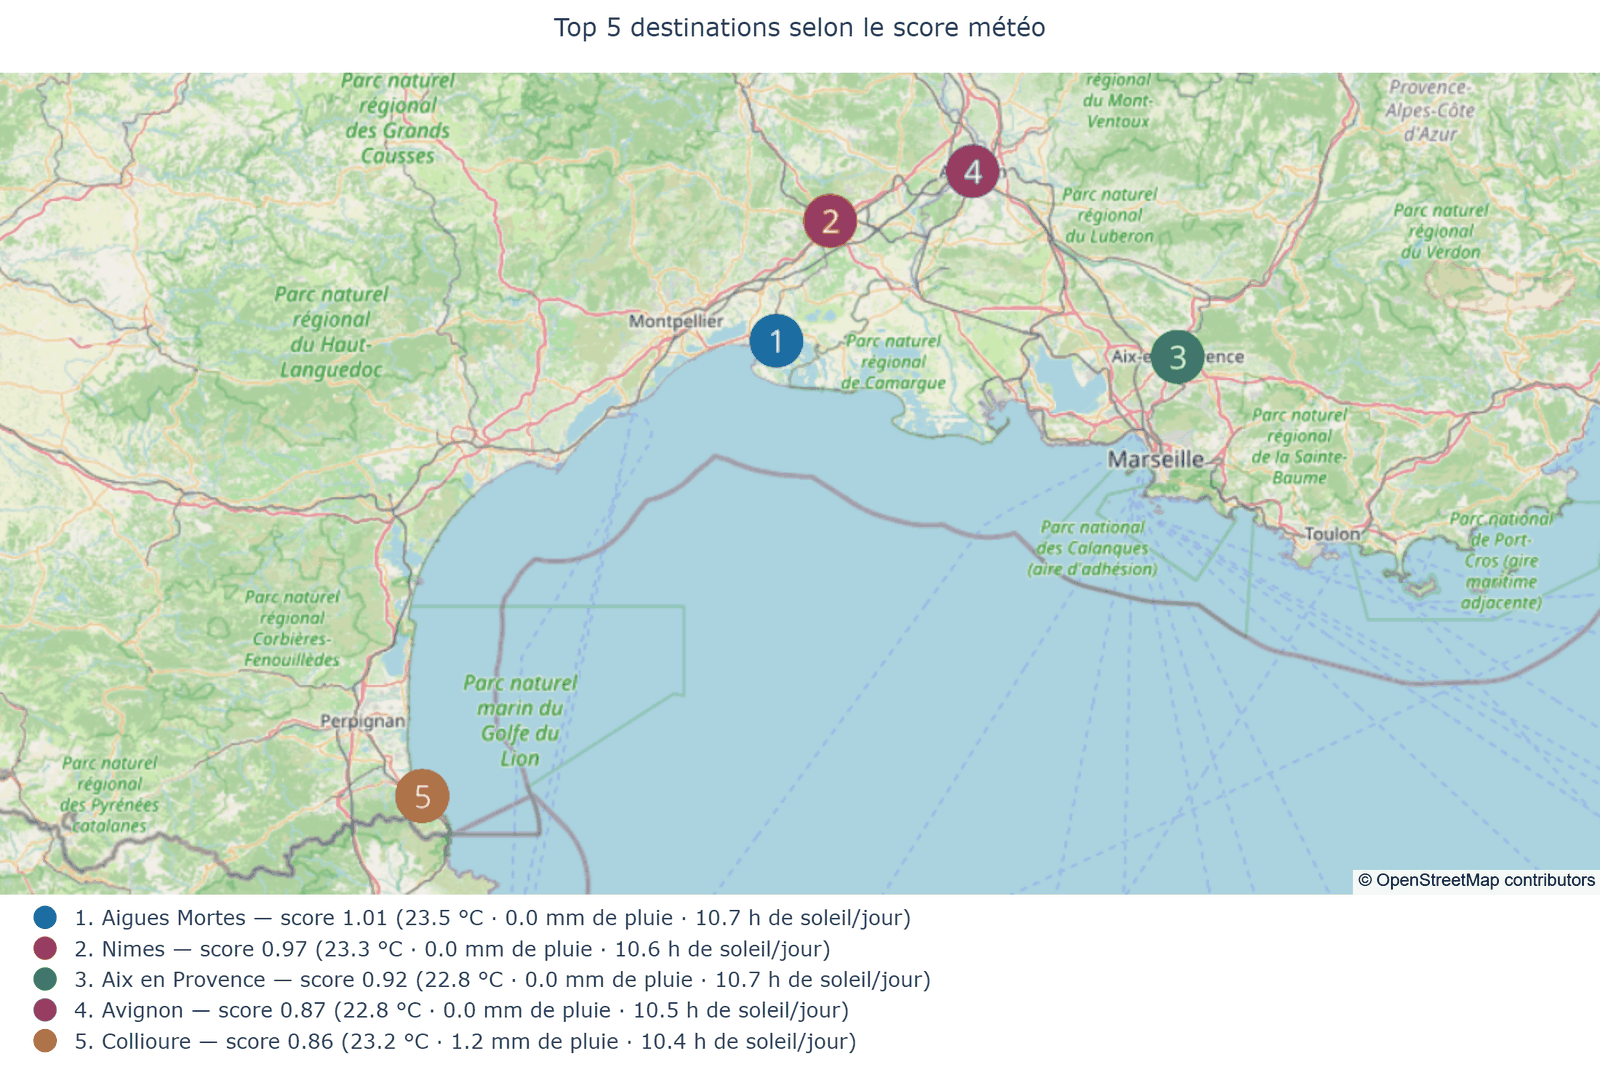

Carte « hotels » : export PNG impossible dans cette exécution (navigateur Chromium absent, ou fond de carte non chargé hors ligne) ; HTML écrit : top20_hotels.html
Image affichée : top20_hotels.png, dernier export PNG réussi (il peut dater d'une exécution antérieure).


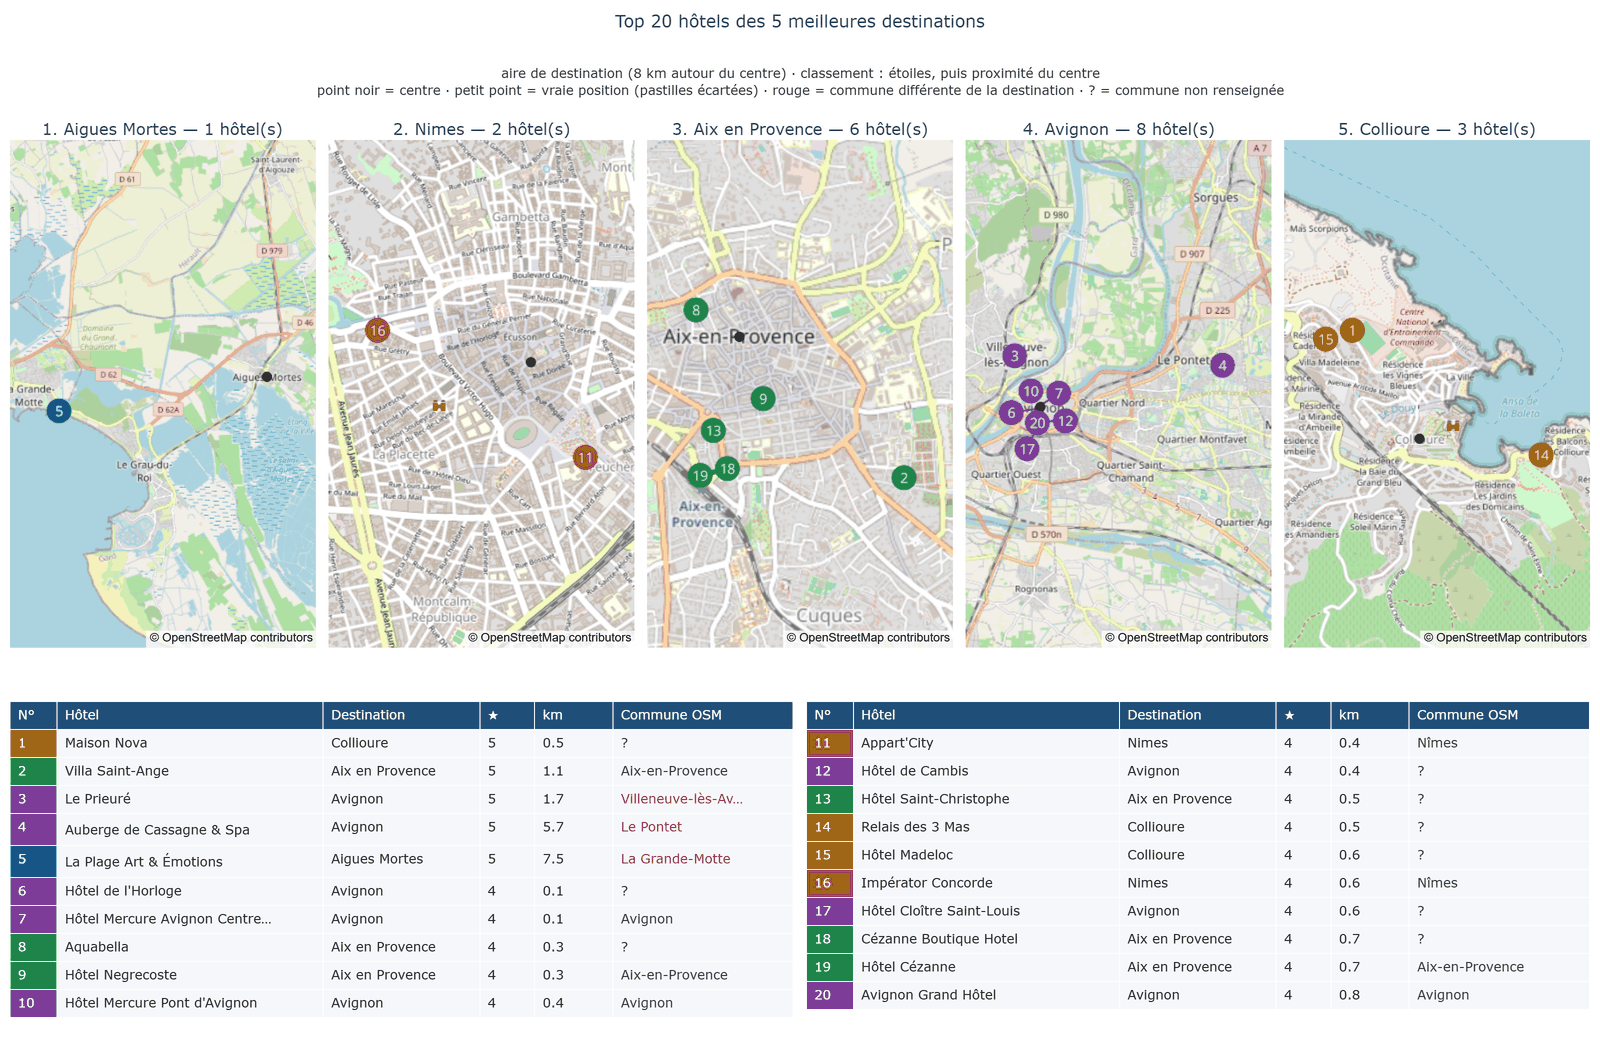

In [17]:
from kayak.cartes import (  # noqa: E402
    carte_destinations,
    carte_hotels,
    enregistrer,
    selectionner_top_hotels,
)

villes_curated = lire_parquet(lake, f"curated/villes/date={DATE}/villes.parquet")
# La carte mentionne un échantillon limité seulement si les archives de la collecte le sont.
diagnostic = diagnostic_troncature(lake)
mention = (
    f"20 meilleurs parmi au plus {diagnostic['plafond']} hôtels OSM par ville"
    if diagnostic["villes_plafonnees"]
    else None
)
print("Archives Overpass plafonnées (ancienne requête) pour cette collecte :",
      diagnostic["villes_plafonnees"], "sur", diagnostic["villes"],
      "villes ; mention d'échantillon :",
      mention or "aucune")
chemins = {
    "destinations": enregistrer(carte_destinations(villes_curated), "top5_destinations"),
    "hotels": enregistrer(
        carte_hotels(enrichi, villes_curated, note_echantillon=mention), "top20_hotels"
    ),
}


for nom, chemin in chemins.items():
    if "png" in chemin:
        afficher(image_allegee(chemin["png"]))
        continue
    print(f"Carte « {nom} » : export PNG impossible dans cette exécution (navigateur Chromium "
          f"absent, ou fond de carte non chargé hors ligne) ; HTML écrit : {chemin['html'].name}")
    precedent = chemin["html"].with_suffix(".png")
    if precedent.is_file():
        print(f"Image affichée : {precedent.name}, dernier export PNG réussi (il peut dater "
              "d'une exécution antérieure).")
        afficher(image_allegee(precedent))

### L'aire de destination (8 km) n'est pas la commune

Les hôtels sont cherchés dans un rayon de 8 km autour du centre de la destination : une
destination est une zone, pas un point. Mais ce rayon dépasse parfois la commune. Le calcul
suivant mesure, pour les 20 hôtels du top, la distance au centre et la commune OpenStreetMap
quand elle est renseignée.

In [18]:
top20 = selectionner_top_hotels(enrichi, villes_curated)
hors = top20[top20["hors_commune"].eq(True)]
print(f"Parmi les 20 hôtels du top : {len(hors)} sont dans une autre commune que leur destination "
      f"(commune OSM connue), {top20['distance_km'].gt(5).sum()} sont à plus de 5 km du centre.")
print(top20["ville"].value_counts().rename("hôtels du top 20").to_string())
print(hors[["rang_hotel", "nom", "ville", "commune", "distance_km"]].to_string(index=False))
couverture = enrichi["commune"].notna().mean()
loin_sans_commune = enrichi[enrichi["commune"].isna() & enrichi["distance_km"].gt(5)]
print(f"\nPart des hôtels dont la commune est renseignée : {couverture:.0%} : le marquage est "
      "donc un indice partiel ;")
print(f"{len(loin_sans_commune)} hôtels sans commune connue sont pourtant à plus de 5 km du "
      "centre de leur destination : la distance, elle, est connue pour tous.")

Parmi les 20 hôtels du top : 3 sont dans une autre commune que leur destination (commune OSM connue), 2 sont à plus de 5 km du centre.
ville
Avignon            8
Aix en Provence    6
Collioure          3
Nimes              2
Aigues Mortes      1
 rang_hotel                       nom         ville                commune  distance_km
          3                Le Prieuré       Avignon Villeneuve-lès-Avignon        1.743
          4 Auberge de Cassagne & Spa       Avignon              Le Pontet        5.670
          5   La Plage Art & Émotions Aigues Mortes        La Grande-Motte        7.518

Part des hôtels dont la commune est renseignée : 21% : le marquage est donc un indice partiel ;
530 hôtels sans commune connue sont pourtant à plus de 5 km du centre de leur destination : la distance, elle, est connue pour tous.


**Le marquage « hors commune » a des faux positifs.** Il compare le nom de la commune
OpenStreetMap à celui de la destination. Une **commune déléguée ou associée** à la destination
(Seynod et Annecy-le-Vieux pour Annecy, Lomme pour Lille) compte donc comme une autre commune,
alors qu'elle appartient à la destination. Le calcul suivant les dénombre avec une liste de
contrôle (non utilisée par l'ETL), puis montre les couples les plus fréquents, dont la plupart
sont de vraies communes voisines (banlieue de Paris, Le Grau-du-Roi pour Aigues-Mortes...).

In [19]:
ASSOCIEES = {  # liste de contrôle : (destination, commune déléguée ou associée)
    ("Annecy", "Annecy-le-Vieux"), ("Annecy", "Seynod"), ("Annecy", "Cran-Gevrier"),
    ("Annecy", "Meythet"), ("Annecy", "Pringy"), ("Lille", "Lomme"), ("Lille", "Hellemmes"),
}
marques = enrichi[enrichi["hors_commune"].eq(True)]
faux = marques[
    [(v, c) in ASSOCIEES for v, c in zip(marques["ville"], marques["commune"], strict=True)]
]
print(f"Hôtels marqués « hors commune » : {len(marques)} ; faux positifs identifiés avec la liste "
      f"de contrôle : {len(faux)} ({faux.groupby(['ville', 'commune']).size().to_dict()}).")
print("\nCouples (destination, commune) les plus fréquents parmi les hôtels marqués :")
couples_marques = marques.groupby(["ville", "commune"]).size().sort_values(ascending=False)
print(couples_marques.head(8).to_string())

Hôtels marqués « hors commune » : 230 ; faux positifs identifiés avec la liste de contrôle : 6 ({('Annecy', 'Annecy-le-Vieux'): 1, ('Annecy', 'Seynod'): 1, ('Lille', 'Lomme'): 4}).

Couples (destination, commune) les plus fréquents parmi les hôtels marqués :
ville          commune            
Aigues Mortes  Le Grau-du-Roi         10
Paris          Pantin                  9
Lille          Villeneuve-d'Ascq       9
Paris          Issy-les-Moulineaux     7
               Puteaux                 7
Toulouse       Blagnac                 6
Aigues Mortes  La Grande-Motte         5
Biarritz       Bidart                  5


**Option : privilégier les hôtels de la commune.** `selectionner_top_hotels(...,
privilegier_commune=True)` fait reculer, derrière tous les autres, les hôtels dont
OpenStreetMap indique une **autre commune** que la destination. Les hôtels de commune inconnue
ne sont pas pénalisés (la commune n'est connue que pour une minorité d'hôtels : les pénaliser
reviendrait à classer d'après la qualité de la saisie, pas celle des hôtels). L'option n'est
pas le choix par défaut parce que la définition retenue des « hôtels d'une destination » est
l'aire de 8 km ; elle sert à mesurer ce que change l'exclusion des hôtels d'autres communes.

In [20]:
par_commune = selectionner_top_hotels(enrichi, villes_curated, privilegier_commune=True)
comparaison = pd.concat(
    {
        "aire de 8 km (défaut)": top20.set_index("rang_hotel")[["nom", "ville", "etoiles"]],
        "commune privilégiée": par_commune.set_index("rang_hotel")[["nom", "ville", "etoiles"]],
    },
    axis=1,
)
partage = len(set(top20["hotel_id"]) & set(par_commune["hotel_id"]))
print(f"Hôtels communs aux deux classements : {partage} sur {len(top20)}")
print("Hôtels hors commune dans le top : "
      f"{len(hors)} (aire de 8 km) contre {par_commune['hors_commune'].eq(True).sum()} "
      "(commune privilégiée)")
# Dernière expression de la cellule : Jupyter l'affiche (d'où l'exception à la règle B018).
comparaison  # noqa: B018

Hôtels communs aux deux classements : 17 sur 20
Hôtels hors commune dans le top : 3 (aire de 8 km) contre 0 (commune privilégiée)


aire de 8 km (défaut)                   \
                                                      nom            ville   
rang_hotel                                                                   
1                                             Maison Nova        Collioure   
2                                        Villa Saint-Ange  Aix en Provence   
3                                              Le Prieuré          Avignon   
4                               Auberge de Cassagne & Spa          Avignon   
5                                 La Plage Art & Émotions    Aigues Mortes   
6                                      Hôtel de l'Horloge          Avignon   
7           Hôtel Mercure Avignon Centre Palais des Papes          Avignon   
8                                               Aquabella  Aix en Provence   
9                                        Hôtel Negrecoste  Aix en Provence   
10                           Hôtel Mercure Pont d'Avignon          Avignon   
11                                            Appart'City            Nimes   
12                                        Hôtel de Cambis          Avignon   
13                                 Hôtel Saint-Christophe  Aix en Provence   
14                                       Relais des 3 Mas        Collioure   
15                                          Hôtel Madeloc        Collioure   
16                                     Impérator Concorde            Nimes   
17                              Hôtel Cloître Saint-Louis          Avignon   
18                                 Cézanne Boutique Hotel  Aix en Provence   
19                                          Hôtel Cézanne  Aix en Provence   
20                                    Avignon Grand Hôtel          Avignon   

                                              commune privilégiée  \
           etoiles                                            nom   
rang_hotel                                                          
1              5.0                                    Maison Nova   
2              5.0                               Villa Saint-Ange   
3              5.0                             Hôtel de l'Horloge   
4              5.0  Hôtel Mercure Avignon Centre Palais des Papes   
5              5.0                                      Aquabella   
6              4.0                               Hôtel Negrecoste   
7              4.0                   Hôtel Mercure Pont d'Avignon   
8              4.0                                    Appart'City   
9              4.0                                Hôtel de Cambis   
10             4.0                         Hôtel Saint-Christophe   
11             4.0                               Relais des 3 Mas   
12             4.0                                  Hôtel Madeloc   
13             4.0                             Impérator Concorde   
14             4.0                      Hôtel Cloître Saint-Louis   
15             4.0                         Cézanne Boutique Hotel   
16             4.0                                  Hôtel Cézanne   
17             4.0                            Avignon Grand Hôtel   
18             4.0                         Novotel Avignon Centre   
19             4.0                                   Best Western   
20             4.0                 Radisson Hôtel Aix-en-Provence   

                                     
                      ville etoiles  
rang_hotel                           
1                 Collioure     5.0  
2           Aix en Provence     5.0  
3                   Avignon     4.0  
4                   Avignon     4.0  
5           Aix en Provence     4.0  
6           Aix en Provence     4.0  
7                   Avignon     4.0  
8                     Nimes     4.0  
9                   Avignon     4.0  
10          Aix en Provence     4.0  
11                Collioure     4.0  
12                Collioure     4.0  
13                    Nimes     4.0  
14                  Avignon     4.0  
15     

### Ce qui a changé entre la première collecte (10/10) et la collecte complète (11/10)

Le palmarès change, et c'est attendu : deux causes, mesurées ci-dessous. (1) **La météo** :
les prévisions du 11/10 ne sont pas celles du 10/10, et les écarts de score entre destinations
sont faibles. (2) **Les hôtels** : la première collecte ne portait que sur les 40 premiers
éléments Overpass de chaque ville ; la seconde porte sur tous les hôtels de l'aire.

In [21]:
villes_avant = lire_parquet(lake, f"curated/villes/date={DATE_PREMIERE}/villes.parquet")
enrichi_avant = lire_parquet(
    lake, f"curated/kayak_enrichi/date={DATE_PREMIERE}/kayak_enrichi.parquet"
)
colonnes = ["rang_meteo", "ville", "temp_max_moy_c", "pluie_totale_mm", "ensoleillement_moy_h",
            "score_meteo"]
avant5 = villes_avant.nsmallest(5, "rang_meteo")[colonnes].reset_index(drop=True)
apres5 = villes_curated.nsmallest(5, "rang_meteo")[colonnes].reset_index(drop=True)
afficher(pd.concat({f"collecte du {DATE_PREMIERE}": avant5, f"collecte du {DATE}": apres5},
                  axis=1).round(2))
sortent = sorted(set(avant5["ville"]) - set(apres5["ville"]))
entrent = sorted(set(apres5["ville"]) - set(avant5["ville"]))
print("Quittent le top 5 :", sortent, "| y entrent :", entrent)
rangs = villes_avant.set_index("ville")["rang_meteo"].to_frame("rang_10_10").join(
    villes_curated.set_index("ville")["rang_meteo"].rename("rang_11_10"))
print(rangs.loc[sortent + entrent].to_string())
mesures = ["temp_max_moy_c", "ensoleillement_moy_h", "score_meteo"]
details = villes_avant.set_index("ville")[mesures].join(
    villes_curated.set_index("ville")[mesures], lsuffix="_10_10", rsuffix="_11_10"
)
print("\nMêmes destinations, mesures météo des deux collectes (la période est la même) :")
print(details.loc[sortent + entrent].round(2).to_string())
ecart = details.filter(like="_11_10").to_numpy() - details.filter(like="_10_10").to_numpy()
ecart_temperature, ecart_soleil = ecart[:, 0].mean(), ecart[:, 1].mean()
print(f"Écart moyen, toutes villes, entre les deux collectes : température maximale "
      f"{ecart_temperature:+.2f} °C, ensoleillement {ecart_soleil:+.2f} h par jour.")
coord_avant = pd.read_csv(lake.chemin_local(f"raw/geocodage/date={DATE_PREMIERE}/coordonnees.csv"))
fusion = coord_avant.merge(coordonnees, on="id_ville", suffixes=("_10_10", "_11_10"))
deplaces = fusion[(fusion["latitude_10_10"] != fusion["latitude_11_10"])
                  | (fusion["longitude_10_10"] != fusion["longitude_11_10"])]
print(f"\nCoordonnées Nominatim différentes d'une collecte à l'autre : {len(deplaces)} villes "
      f"sur {len(fusion)} ({', '.join(deplaces['ville_10_10'])}) : le géocodage n'est pas "
      "parfaitement stable.")
meteo_avant = pd.DataFrame(
    json.loads(x) for x in lake.lire(f"raw/meteo/date={DATE_PREMIERE}/previsions.jsonl")
    .decode("utf-8").splitlines()
)
jours_avant = sorted({p["date"] for previsions in meteo_avant["previsions"] for p in previsions})
print(f"Prévisions de la collecte du {DATE_PREMIERE} : du {jours_avant[0]} au {jours_avant[-1]} ; "
      f"collecte du {DATE} : du {meteo['date'].min()} au {meteo['date'].max()}.")

collecte du 2026-10-10                                                     \
              rang_meteo               ville temp_max_moy_c pluie_totale_mm   
0                      1       Aigues Mortes          23.07             0.0   
1                      2  Bormes les Mimosas          23.10             1.2   
2                      3            Toulouse          23.21             0.0   
3                      4               Nimes          22.79             0.0   
4                      5              Cassis          22.63             0.3   

                                   collecte du 2026-10-11                   \
  ensoleillement_moy_h score_meteo             rang_meteo            ville   
0                10.12        0.92                      1    Aigues Mortes   
1                10.30        0.92                      2            Nimes   
2                 9.95        0.91                      3  Aix en Provence   
3                10.20        0.89                      4          Avignon   
4                10.23        0.87                      5        Collioure   

                                                                   
  temp_max_moy_c pluie_totale_mm ensoleillement_moy_h score_meteo  
0          23.53             0.0                10.70        1.01  
1          23.29             0.0                10.61        0.97  
2          22.84             0.0                10.69        0.92  
3          22.76             0.0                10.47        0.87  
4          23.19             1.2                10.38        0.86

Quittent le top 5 : ['Bormes les Mimosas', 'Cassis', 'Toulouse'] | y entrent : ['Aix en Provence', 'Avignon', 'Collioure']
                    rang_10_10  rang_11_10
ville                                     
Bormes les Mimosas           2          10
Cassis                       5           8
Toulouse                     3           7
Aix en Provence             11           3
Avignon                      7           4
Collioure                    6           5

Mêmes destinations, mesures météo des deux collectes (la période est la même) :
                    temp_max_moy_c_10_10  ensoleillement_moy_h_10_10  score_meteo_10_10  temp_max_moy_c_11_10  ensoleillement_moy_h_11_10  score_meteo_11_10
ville                                                                                                                                                       
Bormes les Mimosas                 23.10                       10.30               0.92                 22.84                       10.23 

In [22]:
top20_avant = selectionner_top_hotels(enrichi_avant, villes_avant)
communs = set(top20_avant["hotel_id"]) & set(top20["hotel_id"])
print(f"Top 20 des hôtels : {len(communs)} hôtels en commun entre les deux collectes sur 20.")
print(f"Hôtels collectés : {len(anciens_hotels)} le {DATE_PREMIERE}, {len(hotels_osm)} le "
      f"{DATE} ; "
      f"hôtels retenus par l'ETL : {len(enrichi_avant)} contre {len(enrichi)}.")
print(f"Hôtels classés 4 étoiles ou plus : {int(enrichi_avant['etoiles'].ge(4).sum())} contre "
      f"{int(enrichi['etoiles'].ge(4).sum())} ; 5 étoiles : "
      f"{int(enrichi_avant['etoiles'].eq(5).sum())} contre {int(enrichi['etoiles'].eq(5).sum())}.")
print(f"Étoiles renseignées : {enrichi['etoiles'].notna().mean():.0%} des hôtels de la collecte "
      f"du {DATE}.")

Top 20 des hôtels : 3 hôtels en commun entre les deux collectes sur 20.
Hôtels collectés : 1202 le 2026-10-10, 4128 le 2026-10-11 ; hôtels retenus par l'ETL : 1130 contre 3997.
Hôtels classés 4 étoiles ou plus : 126 contre 572 ; 5 étoiles : 16 contre 81.
Étoiles renseignées : 46% des hôtels de la collecte du 2026-10-11.


> **Interprétation** : les deux cartes livrent ce que demande l'énoncé. Le top 5 se
> concentre dans le Midi méditerranéen, du Roussillon (Collioure) à la Provence
> (Aix-en-Provence, Avignon) en passant par le Gard (Nîmes, Aigues-Mortes). Le top 20 des
> hôtels de ces cinq villes est classé par étoiles (cinq 5 étoiles en tête, puis des
> 4 étoiles), faute de note des clients : c'est la conséquence directe du contrôle
> anti-robot de Booking.com. Il porte sur tous les hôtels nommés de l'aire de destination de
> 8 km : trois des vingt hôtels sont dans une autre commune que leur destination
> (Villeneuve-lès-Avignon, Le Pontet, La Grande-Motte), ce que montre le marquage en rouge.
> Par rapport à la première collecte, le palmarès a changé (Bormes-les-Mimosas, Cassis et
> Toulouse sortent du top 5 ; Aix-en-Provence, Avignon et Collioure y entrent) et seuls 3 des
> 20 hôtels sont restés : les prévisions ont été révisées entre les deux collectes, et les
> hôtels sont maintenant tous collectés (calculs ci-dessus). Si Kayak obtient un accès
> partenaire aux données de Booking (API d'affiliation), le pipeline réintègre les notes sans
> autre changement : le schéma des hôtels prévoit déjà les colonnes « note » et « nb_avis ».

## 7. Conformité de la collecte (RGPD) et limites

- **Données collectées** : villes, coordonnées, prévisions météo, établissements hôteliers.
  **Aucune donnée personnelle exploitée** : les tables curated et l'entrepôt ne gardent que
  des données d'établissements, sans champ de contact ni avis nominatif.
- **Minimisation** : les moyens de contact que renvoie OpenStreetMap (courriel, téléphone,
  étiquettes `contact:*`, sauf le site web) sont retirés de chaque réponse dès sa réception,
  avant l'archivage, et un courriel ou un numéro cité dans un texte libre est masqué
  (`kayak/collecte/minimisation.py` ; cas réel : la description d'un hôtel de Paris citait
  deux numéros). Les archives brutes des deux collectes, écrites avant cette règle, ont été
  minimisées hors ligne le 19/10/2026, sans nouvelle collecte : 6 882 étiquettes de contact
  retirées, une description masquée. L'exclusion des hôtes particuliers est prévue dans le
  robot Booking, qui n'a pas été relancé le 11/10.
- **Loyauté de la collecte** : robot identifié par son User-Agent, débit volontairement faible
  (une requête par seconde au plus pour Nominatim, une pause d'une seconde entre deux
  requêtes Overpass, une demi-seconde pour Open-Meteo), arrêt immédiat devant un contrôle
  anti-robot. `robots.txt` de Booking.com et de la page source des destinations : archivés
  datés dans le lac, interprétés règle par règle (sections 2 et 3). Chaque requête HTTP de
  la collecte du 11/10 est journalisée (statut, taille, durée ; Booking non relancé).
- **Licences** : OpenStreetMap et Nominatim (ODbL, attribution « © les contributeurs
  d'OpenStreetMap », affichée sur les cartes) ; Open-Meteo (CC BY 4.0 ; API gratuite
  réservée à un usage non commercial).
- **Conservation** : collectes datées dans le data lake ; en production, règle de cycle de vie
  S3 (suppression des zones brutes après 90 jours, par exemple).
- **Limites** :
  - **deux collectes** : tous les résultats reposent sur la collecte complète du 11/10 ; celle
    du 10/10 (échantillon plafonné à 40 éléments par ville, quatre hôtels de commune Kehl,
    cinq établissements allemands au total) est une archive, conservée avec la preuve du
    refus de Booking.com ;
  - hôtels cherchés dans une **aire de destination de 8 km**, qui dépasse parfois la commune ;
    la commune n'est renseignée dans OpenStreetMap que pour une minorité d'hôtels (21 %), et
    le marquage « hors commune » a des faux positifs (communes déléguées ou associées) ;
  - hôtels sans note des clients (repli OpenStreetMap), classés par étoiles, qui ne sont
    renseignées que pour 46 % d'entre eux, puis par proximité du centre ;
  - **extraction Booking non validée sur une page réelle** (bloquée par le contrôle
    anti-robot) ; le statut HTTP des réponses du 10/10 n'a pas été archivé ;
  - le serveur Overpass principal a répondu « occupé » (504) à une requête sur deux, qu'il a
    fallu répéter : aucune réponse partielle n'a été retenue, mais la collecte est lente ;
  - le géocodage Nominatim n'est pas parfaitement stable (2 villes ont changé de centre
    entre les deux collectes) ;
  - météo d'un instantané de 7 jours : le classement change d'une collecte à l'autre ;
  - l'extensibilité (S3, Spark) n'est pas démontrée au-delà de 35 villes sur un poste : les
    chiffres de volume de la section 1 sont mesurés, ceux du scénario sont des extrapolations ;
  - le passage sur AWS (S3, RDS) demande un compte et se fait par deux variables
    d'environnement (voir le README) ; le mode S3 n'a été testé qu'avec un faux client.

*Copyright © 2026 · voir le fichier LICENSE du dépôt*